## **Import libraries & load dataset**
## **Q1**

---



In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


In [7]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
df

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,Satisfied


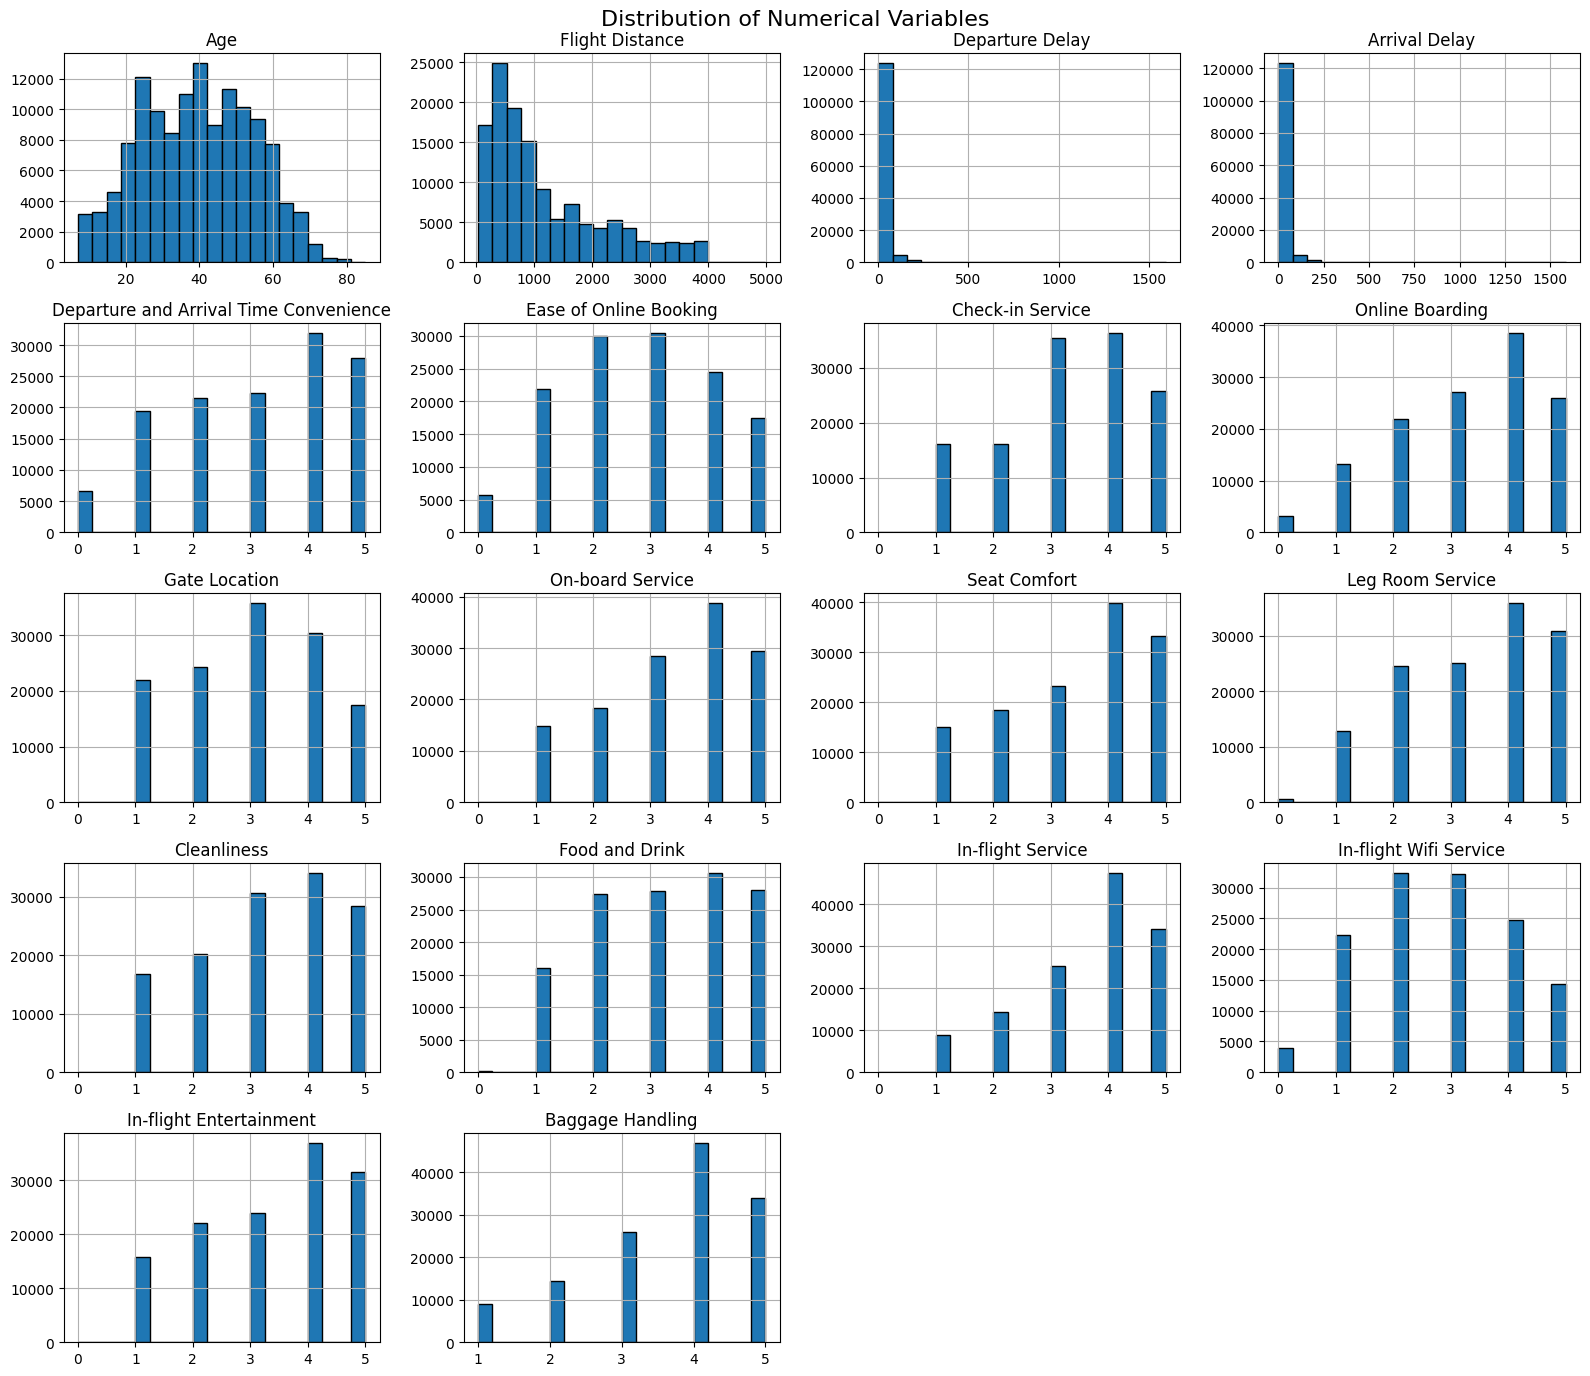

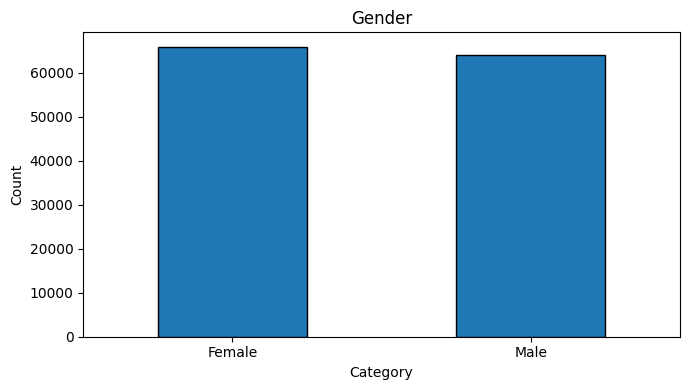

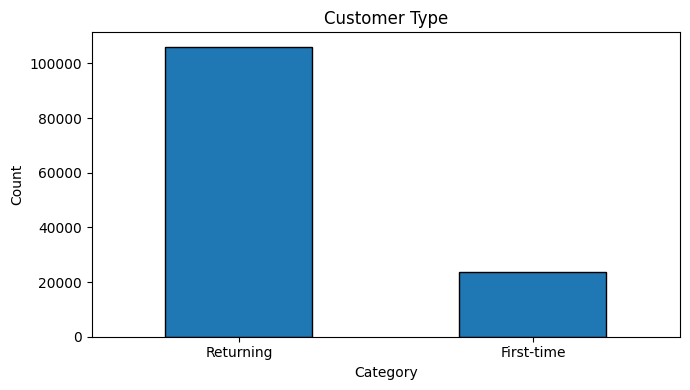

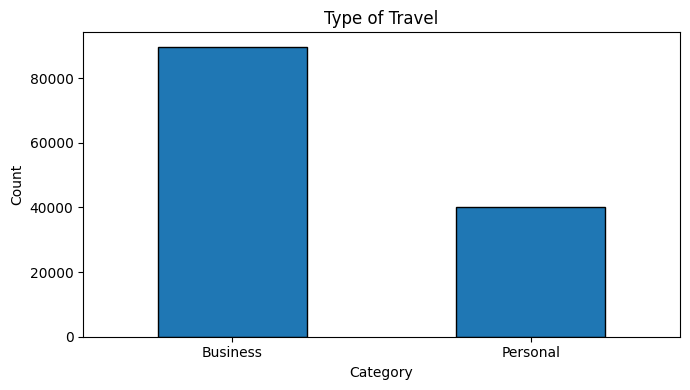

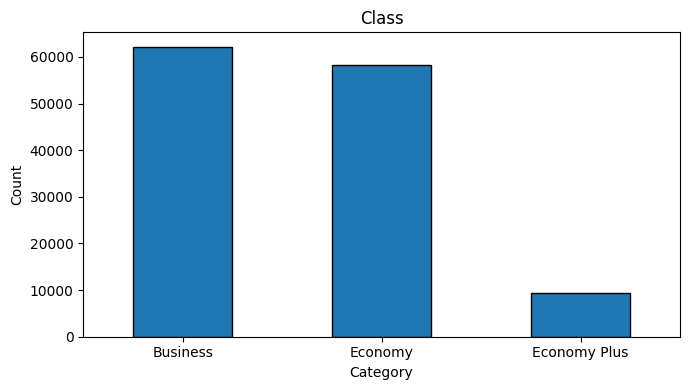

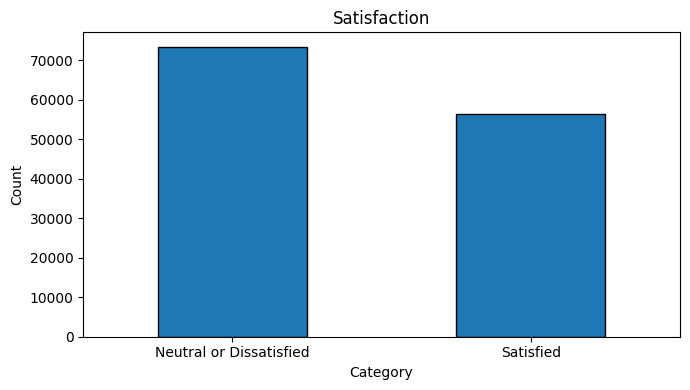

Satisfaction
Neutral or Dissatisfied    56.6
Satisfied                  43.4
Name: proportion, dtype: float64


In [8]:
# numeric variables
numeric_vals = df.select_dtypes(include='number').columns.drop('ID')

df[numeric_vals].hist(figsize=(16, 14),bins=20,edgecolor='black')
plt.suptitle('Distribution of Numerical Variables', fontsize=16)
plt.tight_layout()
plt.show()

# categorical variables
categorical_cols = ['Gender','Customer Type','Type of Travel','Class','Satisfaction']

for col in categorical_cols:
    plt.figure(figsize=(7, 4))
    df[col].value_counts().plot(kind='bar', edgecolor='black')
    plt.title(col)
    plt.xlabel('Category')
    plt.ylabel('Count')
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# class inbalance
print(df['Satisfaction'].value_counts(normalize=True).round(3) * 100)

# Q1: η κλάση "Neutral or Dissatisfied" υπερισχύει στο dataset και έχει ποσοστό εμφάνισης 56.6%, ενώ η Satisfied έχει ποσοστό εμφάνισης 43.4%.


# Q2




In [9]:
# encoding
df['Gender'] = df['Gender'].map({'Male':0,'Female':1})
df['Customer Type'] = df['Customer Type'].map({'First-time':0,'Returning':1})
df['Type of Travel'] = df['Type of Travel'].map({'Personal':0,'Business':1})
df['Satisfaction'] = df['Satisfaction'].map({'Neutral or Dissatisfied':0,'Satisfied':1})
df = pd.get_dummies(df, columns=['Class'], dtype=int)
df

,ID,Gender,Age,Customer Type,Type of Travel,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,...,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction,Class_Business,Class_Economy,Class_Economy Plus
0,1,0,48,0,1,821,2,5.0,3,3,...,5,5,5,3,5,5,0,1,0,0
1,2,1,35,1,1,821,26,39.0,2,2,...,5,3,5,2,5,5,1,1,0,0
2,3,0,41,1,1,853,0,0.0,4,4,...,5,5,3,4,3,3,1,1,0,0
3,4,0,50,1,1,1905,0,0.0,2,2,...,4,4,5,2,5,5,1,1,0,0
4,5,1,49,1,1,3470,0,1.0,3,3,...,5,4,3,3,3,3,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,0,28,1,0,447,2,3.0,4,4,...,4,4,5,4,4,4,0,0,0,1
129876,129877,0,41,1,0,308,0,0.0,5,3,...,2,2,4,3,2,5,0,0,0,1
129877,129878,0,42,1,0,337,6,14.0,5,2,...,3,3,4,2,3,5,0,0,0,1
129878,129879,0,50,1,0,337,31,22.0,4,4,...,3,3,4,5,3,5,1,0,0,1


# Q3

In [10]:
# train and test set split
x = df.drop(columns= ['ID','Satisfaction'])
y = df['Satisfaction']
x = x.to_numpy()
y = y.to_numpy()

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.3, random_state=0)
print('x train:', x_train.shape, 'x test:', x_test.shape)
print('y train:', y_train.shape, 'y test:', y_test.shape)

# y = satisfaction: train size x 1, test size x 1

x train: (90916, 24) x test: (38964, 24)
y train: (90916,) y test: (38964,)


# Q4



In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# scaling in these 4 vars
numeric_vals=['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']
numeric_idx=[df.drop(columns=['ID', 'Satisfaction']).columns.get_loc(col) for col in numeric_vals]

#print(df.isna().sum())
#print(df.isna().sum()[df.isna().sum() > 0])
# simple imputer for the nan values
imputer = SimpleImputer(strategy='median')
x_train[:, numeric_idx] = imputer.fit_transform(x_train[:, numeric_idx])
x_test[:, numeric_idx] = imputer.transform(x_test[:, numeric_idx])

# scaler
scaler = StandardScaler()
x_train[:, numeric_idx] = scaler.fit_transform(x_train[:, numeric_idx])
x_test[:, numeric_idx] = scaler.transform(x_test[:, numeric_idx])

### some tests
#print('train nan:', np.isnan(x_train).sum())
#print('test nan:', np.isnan(x_test).sum())
#print(x_train[:, numeric_idx].mean(axis=0))
#print(x_train[:, numeric_idx].std(axis=0))

# χρησιμοποιησαμε τον standar scaler για τις αριθμητικές μεταβλητές, επειδή ο knn χρησιμοποιεί euclidean distance, κι ετσι χωρις scaling θα είχαμε μεταβλητές με μεγαλύτερο εύρος τιμών.
# Κάτι τέτοιο θα επηρέαζε πολύ περισσότερο τον υπολογισμό της απόστασης στον knn. Κάναμε κανονικοποίηση με βάση το training set.

# Q5


In [ ]:
# k = 3,5,15,51,151,sqrt(N)

from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

k = [3,5,15,51,151,int(np.sqrt(len(x_train)))]
weights = ['distance','uniform']
results = []

# looping!
for k in k:
  for w in weights:
      knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean', n_jobs=-1)
      knn.fit(x_train, y_train)
      train_acc = knn.score(x_train, y_train)
      test_acc = knn.score(x_test, y_test)
      results.append([k, w, train_acc, test_acc])
results_df = pd.DataFrame(results, columns=['k','weights','train accuracy', 'test accuracy'])

results_df

# print(results_df.loc[results_df['test accuracy'].idxmax()])

In [ ]:
# ο καλυτερος συνδιασμος ειναι k=5 με weights='distance', με train accuracy 100% και test accuracy 92,96%. Η επιλογη distance δίνει μεγαλυτερο βαρος/αξια στους κοντινοτερους γειτονες.